In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

El contrato fija la entrega del proyecto en la semana 27, con una penalización de 6 k€ por cada semana de retraso. Se adjuntan las prelaciones, la duración normal y la tope de cada actividad (semanas) y su coste unitario de reducción (k€/semana). Las actividades B, E no pueden acelerarse.

In [3]:
pregunta_1 = "1. Determine la duración del proyecto con las duraciones normales y la penalización a la que se expone si no se reduce.  "
pregunta_2 = "2. Aplique el algoritmo de Ackoff-Sasieni para llevar el proyecto a la semana 27, anotando el sobrecoste de cada paso.  "
pregunta_3 = "3. Compare en cada paso el sobrecoste con la penalización evitada y decida cuántas semanas conviene reducir. ¿Cuál es el coste total mínimo (sobrecoste más penalización)?  "
pregunta_4 = "4. ¿Qué habría cambiado si las actividades no acelerables hubieran sido críticas? Compruébelo sobre el camino crítico.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Determine la duración del proyecto con las duraciones normales y la penalización a la que se expone si no se reduce.  

2. Aplique el algoritmo de Ackoff-Sasieni para llevar el proyecto a la semana 27, anotando el sobrecoste de cada paso.  

3. Compare en cada paso el sobrecoste con la penalización evitada y decida cuántas semanas conviene reducir. ¿Cuál es el coste total mínimo (sobrecoste más penalización)?  

4. ¿Qué habría cambiado si las actividades no acelerables hubieran sido críticas? Compruébelo sobre el camino crítico.  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, cap_duration, ucr   
    ('A'     , '---'      , 5       , 4           , 9     ),
    ('B'     , '---'      , 2       , 2           , np.inf),
    ('C'     , '---'      , 5       , 2           , 4     ),
    ('D'     , 'B,C'      , 7       , 4           , 4     ),
    ('E'     , 'A,B'      , 8       , 8           , np.inf),
    ('F'     , 'D,E'      , 7       , 5           , 5     ),
    ('G'     , 'F'        , 3       , 1           , 9     ),
    ('H'     , 'F'        , 7       , 4           , 1     ),
    ('I'     , 'G'        , 6       , 4           , 6     ),
], columns=['activity', 'predecessor', 'duration', 'cap_duration', 'ucr']).set_index('activity')
datos_enunciado

,predecessor,duration,cap_duration,ucr
activity,,,,
A,---,5,4,9.0
B,---,2,2,inf
C,---,5,2,4.0
D,"B,C",7,4,4.0
E,"A,B",8,8,inf
F,"D,E",7,5,5.0
G,F,3,1,9.0
H,F,7,4,1.0
I,G,6,4,6.0


# Resolución

In [5]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Determine la duración del proyecto con las duraciones normales y la penalización a la que se expone si no se reduce.  

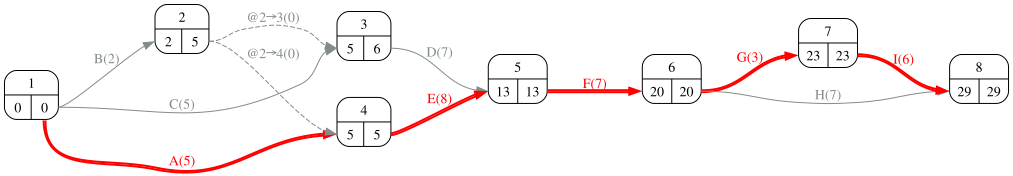

In [7]:
#| fig-cap: "Grafo PERT con las duraciones normales y el camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [8]:
plazo_contrato, penalizacion_semanal = 27, 6
duracion_normal = proyecto.duration(datos_proyecto['duration'])
camino_critico = proyecto.display_critical_path(datos_proyecto['duration'])
retraso = max(0, duracion_normal - plazo_contrato)
Markdown(f'Con las duraciones normales el proyecto dura {duracion_normal} semanas, {retraso} más que el plazo: '
         f'penalización de {retraso} × {penalizacion_semanal} = {retraso * penalizacion_semanal} k€.')

- Route_1 :	A, E, F, G, I <br> 

Con las duraciones normales el proyecto dura 29 semanas, 2 más que el plazo: penalización de 2 × 6 = 12 k€.

## Apartado 2

In [9]:
display(Markdown(pregunta_2))

2. Aplique el algoritmo de Ackoff-Sasieni para llevar el proyecto a la semana 27, anotando el sobrecoste de cada paso.  

En cada paso del algoritmo de Ackoff-Sasieni se acorta una semana la ruta (o rutas) crítica(s) eligiendo, entre las actividades críticas con margen, la combinación de menor CUR que reduzca *todas* las rutas críticas a la vez. Cuando hay varias rutas críticas sin actividades comunes baratas hay que acortar una actividad de cada una, y el coste del paso es la suma. La tabla muestra, para cada ruta, el CUR de sus actividades y su duración tras cada paso; las últimas filas, el margen de reducción que le queda a cada actividad.

In [10]:
#| tbl-cap: "Algoritmo de Ackoff-Sasieni"
#| label: tbl-ackoff
tabla_ackoff, pasos, duraciones_reducidas, margen_restante = proyecto.ackoff(
    durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr'], reduction=2, report=False)
tabla_ackoff

,A,B,C,D,E,F,G,H,I,0,1,2
Route_1,9.0,,,,inf,5.0,9.0,,6.0,29.0,28.0,27.0
Route_2,9.0,,,,inf,5.0,,1.0,,27.0,26.0,25.0
Route_3,,inf,,4.0,,5.0,9.0,,6.0,25.0,24.0,23.0
Route_4,,inf,,4.0,,5.0,,1.0,,23.0,22.0,21.0
Route_5,,inf,,,inf,5.0,9.0,,6.0,26.0,25.0,24.0
Route_6,,inf,,,inf,5.0,,1.0,,24.0,23.0,22.0
Route_7,,,4.0,4.0,,5.0,9.0,,6.0,28.0,27.0,26.0
Route_8,,,4.0,4.0,,5.0,,1.0,,26.0,25.0,24.0
0,1.0,0.0,3.0,3.0,0.0,2.0,2.0,3.0,2.0,,,
1,1.0,0.0,3.0,3.0,0.0,1.0,2.0,3.0,2.0,,,


In [11]:
resumen = pd.DataFrame({'actividades acortadas': [', '.join(acts) for acts in pasos.values()],
                        'sobrecoste del paso': [sum(datos_proyecto.loc[acts, 'ucr']) for acts in pasos.values()]},
                       index=pd.Index(range(1, len(pasos) + 1), name='paso'))
resumen['duración'] = duracion_normal - resumen.index
resumen['sobrecoste acumulado'] = resumen['sobrecoste del paso'].cumsum()
resumen

,actividades acortadas,sobrecoste del paso,duración,sobrecoste acumulado
paso,,,,
1,F,5.0,28,5.0
2,F,5.0,27,10.0


## Apartado 3

In [12]:
display(Markdown(pregunta_3))

3. Compare en cada paso el sobrecoste con la penalización evitada y decida cuántas semanas conviene reducir. ¿Cuál es el coste total mínimo (sobrecoste más penalización)?  

In [13]:
decision = resumen.copy()
decision['penalización evitada'] = penalizacion_semanal
decision['conviene'] = decision['sobrecoste del paso'] < penalizacion_semanal
decision['coste total (sobrecoste + penalización)'] = decision['sobrecoste acumulado'] + penalizacion_semanal * (decision['duración'] - plazo_contrato).clip(lower=0)
decision

,actividades acortadas,sobrecoste del paso,duración,sobrecoste acumulado,penalización evitada,conviene,coste total (sobrecoste + penalización)
paso,,,,,,,
1,F,5.0,28,5.0,6,True,11.0
2,F,5.0,27,10.0,6,True,10.0


In [14]:
sin_reducir = penalizacion_semanal * retraso
mejor = decision['coste total (sobrecoste + penalización)'].idxmin()
coste_mejor = decision.loc[mejor, 'coste total (sobrecoste + penalización)']
Markdown(f'''Sin reducir, la penalización sería de {sin_reducir} k€. Conviene dar cada paso mientras su sobrecoste sea menor que la penalización de la semana que evita ({penalizacion_semanal} k€); el coste total mínimo es {coste_mejor:.0f} k€ y se alcanza reduciendo {mejor} semana(s), hasta una duración de {duracion_normal - mejor} semanas.''')

Sin reducir, la penalización sería de 12 k€. Conviene dar cada paso mientras su sobrecoste sea menor que la penalización de la semana que evita (6 k€); el coste total mínimo es 10 k€ y se alcanza reduciendo 2 semana(s), hasta una duración de 27 semanas.

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. ¿Qué habría cambiado si las actividades no acelerables hubieran sido críticas? Compruébelo sobre el camino crítico.  

In [16]:
no_acelerables = datos_proyecto.index[np.isinf(datos_proyecto['ucr'])].tolist()
criticas = sorted(set(a for acts in proyecto.critical_path(datos_proyecto['duration']).values() for a in acts))
en_critico = [a for a in no_acelerables if a in criticas]
Markdown(f'''Las actividades no acelerables son {", ".join(no_acelerables)}; de ellas, {", ".join(en_critico) or "ninguna"} está en el camino crítico. Una actividad no acelerable en el camino crítico no impide reducir el proyecto mientras haya otras actividades críticas con margen, pero cuando todas las rutas críticas pasan por actividades sin margen la duración tope queda fijada y ninguna cantidad de dinero la rebaja.''')

Las actividades no acelerables son B, E; de ellas, E está en el camino crítico. Una actividad no acelerable en el camino crítico no impide reducir el proyecto mientras haya otras actividades críticas con margen, pero cuando todas las rutas críticas pasan por actividades sin margen la duración tope queda fijada y ninguna cantidad de dinero la rebaja.